# DWD-Wetterdaten Berlin-Tempelhof: 2020 bis heute

Dieses Notebook lädt die bereits heruntergeladene CSV mit täglichen Messwerten der DWD-Station Berlin-Tempelhof (Stations-ID 00433). Die Datei enthält Temperaturminimum, Temperaturmaximum, Tagesmitteltemperatur, Niederschlagsmenge und Sonnenscheindauer.

Die Werte stammen aus den DWD-Tagesdaten (CDC). Temperaturen sind in °C, Niederschlag in mm und Sonnenscheindauer in Stunden angegeben. Leere CSV-Felder stehen für DWD-Fehlwerte. Der letzte beim Download verfügbare Datensatz ist vom 1. November 2026.

In [3]:
import csv
from pathlib import Path

csv_pfad = Path("DWD_Berlin_Tempelhof_2020_bis_heute.csv")
with csv_pfad.open(encoding="utf-8", newline="") as csv_datei:
    wetterdaten = list(csv.DictReader(csv_datei))

print(f"Geladene Tagesdatensätze: {len(wetterdaten)}")
print("Erste drei Zeilen:")
wetterdaten[:3]

Geladene Tagesdatensätze: 2497
Erste drei Zeilen:


[{'datum': '2020-01-01',
  'temp_min_c': '-1.7',
  'temp_max_c': '5.7',
  'temp_durch_c': '2.7',
  'niederschlagsmenge_mm': '0.0',
  'sonnenstunden_h': '1.5'},
 {'datum': '2020-01-02',
  'temp_min_c': '-3.8',
  'temp_max_c': '6.7',
  'temp_durch_c': '0.9',
  'niederschlagsmenge_mm': '0.0',
  'sonnenstunden_h': '6.2'},
 {'datum': '2020-01-03',
  'temp_min_c': '1.5',
  'temp_max_c': '7.2',
  'temp_durch_c': '4.6',
  'niederschlagsmenge_mm': '4.3',
  'sonnenstunden_h': '0.0'}]

## Tagesmitteltemperatur nach Kalenderjahr

Die Linien zeigen die Tagesmitteltemperatur eines Jahres jeweils entlang des Kalenderverlaufs. Dadurch lassen sich saisonale Verläufe und Unterschiede zwischen Jahren direkt vergleichen. Der 29. Februar liegt in der Grafik zwischen dem 28. Februar und dem 1. März; unvollständige Jahre enden mit dem letzten vorhandenen Messwert.

Für die Darstellung wird `matplotlib` verwendet.

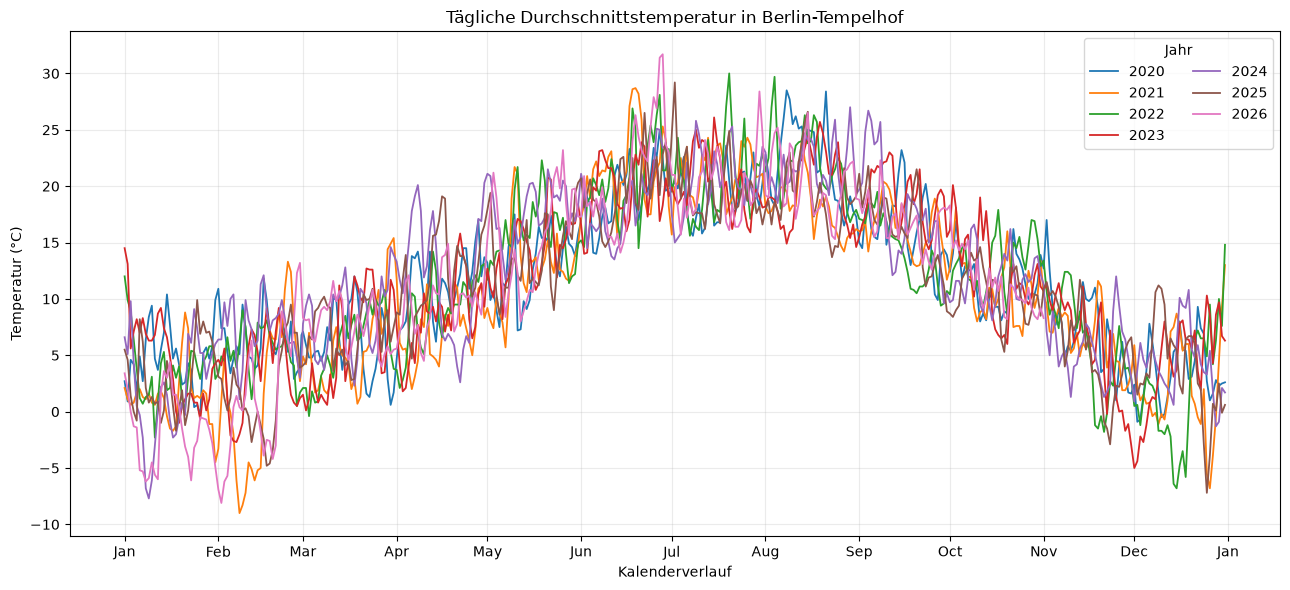

In [5]:
from datetime import datetime

import matplotlib.dates as mdates
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 6))
jahre = sorted({zeile["datum"][:4] for zeile in wetterdaten})

for jahr in jahre:
    x_werte = []
    y_werte = []
    for zeile in wetterdaten:
        if zeile["datum"][:4] != jahr or not zeile["temp_durch_c"]:
            continue
        datum = datetime.strptime(zeile["datum"], "%Y-%m-%d")
        if datum.month == 2 and datum.day == 29:
            kalenderdatum = datetime(2001, 2, 28, 12)
        else:
            kalenderdatum = datetime(2001, datum.month, datum.day)
        x_werte.append(kalenderdatum)
        y_werte.append(float(zeile["temp_durch_c"]))
    ax.plot(x_werte, y_werte, label=jahr, linewidth=1.3)

ax.set_title("Tägliche Durchschnittstemperatur in Berlin-Tempelhof")
ax.set_xlabel("Kalenderverlauf")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(True, alpha=0.25)
ax.legend(title="Jahr", ncols=2)
fig.tight_layout()
plt.show()

## Interpretation: Was lässt sich aus dem Diagramm ableiten?

- **Saisonaler Rhythmus:** In jedem Jahr steigen die Tagesmittel typischerweise vom Winter zum Sommer an und fallen danach wieder. Der Jahresverlauf ist deutlich stärker als viele kurzfristige Unterschiede zwischen einzelnen Tagen.
- **Unterschiede zwischen vollständigen Jahren:** Das höchste Jahresmittel im vollständigen Zeitraum 2020–2025 hat 2024 mit **12,31 °C**; das niedrigste hat 2021 mit **10,49 °C**. Einzelne warme oder kalte Tage können davon stark abweichen.
- **2026 nur vorläufig vergleichen:** Das Jahr enthält Daten vom 1. Januar bis zum 1. November (**305 Tage**), kein vollständiges Jahr. Sein bisheriges Mittel von **12,20 °C** ist deshalb nicht direkt mit den Jahresmitteln vollständiger Jahre vergleichbar.
- **Keine sichere Langzeitprognose:** Die Grafik zeigt Wetterverläufe einer einzelnen Station über wenige Jahre. Daraus allein lässt sich kein belastbarer langfristiger Klimatrend ableiten; dafür wären längere Reihen und eine statistische Auswertung nötig.

In [ ]:
## Typischer Ablauf einer Datenanalyse

1. **Fragestellung festlegen**  
    Welche Entwicklung oder welcher Zusammenhang soll untersucht werden?

2. **Daten laden**  
    Die CSV-Datei mit den täglichen Messwerten einlesen.

3. **Daten prüfen und bereinigen**  
    Datumsangaben und Messwerte kontrollieren, fehlende Werte erkennen und Datentypen vereinheitlichen.

4. **Daten aufbereiten**  
    Beispielsweise Monats- oder Jahreswerte aus Temperatur, Niederschlag und Sonnenscheindauer berechnen.

5. **Daten explorieren**  
    Kennzahlen wie Mittelwert, Minimum und Maximum bestimmen und Verteilungen vergleichen.

6. **Ergebnisse visualisieren**  
    Geeignete Diagramme erstellen, etwa Zeitreihen, Monatsvergleiche oder Streudiagramme.

7. **Ergebnisse interpretieren**  
    Muster und Auffälligkeiten beschreiben und mögliche Einschränkungen berücksichtigen, zum Beispiel unvollständige Jahre oder fehlende Messwerte.

8. **Schlussfolgerungen dokumentieren**  
    Die wichtigsten Erkenntnisse knapp zusammenfassen und die Fragestellung beantworten.

## Prognose der Tagesdurchschnittstemperatur

Das Modell sagt jeweils den Tagesmittelwert für den nächsten Tag voraus. Als Eingaben dienen die Tagesmittel der fünf vorhergehenden Tage sowie der Kalendertag des Prognosetags (1 bis 365). Der 29. Februar wird dem 28. Februar zugeordnet, damit die Jahresposition immer im Bereich 1 bis 365 bleibt.

Die Trainingsbeispiele werden chronologisch aufgebaut. Trainiert wird mit Zielwerten bis einschließlich 2025, getestet mit 2026. Beim Test werden die tatsächlich beobachteten letzten fünf Tage verwendet: Das misst eine tägliche Ein-Tages-Prognose, keine mehrtägige Prognose ohne neue Messungen.

In [8]:
from datetime import date, timedelta

# Messwerte nach Datum indizieren; leere Tagesmittel werden ignoriert.
temperatur_nach_datum = {
    date.fromisoformat(zeile["datum"]): float(zeile["temp_durch_c"])
    for zeile in wetterdaten
    if zeile["temp_durch_c"]
}

def tag_im_jahr(datum):
    if datum.month == 2 and datum.day == 29:
        return 59
    return date(2001, datum.month, datum.day).timetuple().tm_yday

# Jede Zeile: fünf Vortageswerte plus Kalender-Tag des Prognosetags.
merkmale = []
zielwerte = []
zieldaten = []

for zieldatum in sorted(temperatur_nach_datum):
    vergangene_tage = [zieldatum - timedelta(days=abstand) for abstand in range(5, 0, -1)]
    if not all(tag in temperatur_nach_datum for tag in vergangene_tage):
        continue

    kalendertag = tag_im_jahr(zieldatum)
    merkmale.append(
        [temperatur_nach_datum[tag] for tag in vergangene_tage]
        + [kalendertag]
    )
    zielwerte.append(temperatur_nach_datum[zieldatum])
    zieldaten.append(zieldatum)

print(f"Trainingsbeispiele insgesamt: {len(merkmale)}")
print("Eingabewerte je Beispiel: 5 Vortagestemperaturen + Kalendertag (1-365)")
print("Anzahl Eingabewerte:", len(merkmale[0]))
print("Beispiel-Merkmalszeile:", merkmale[0])
print("Beispiel-Zielwert in °C:", zielwerte[0])

Trainingsbeispiele insgesamt: 2492
Eingabewerte je Beispiel: 5 Vortagestemperaturen + Kalendertag (1-365)
Anzahl Eingabewerte: 6
Beispiel-Merkmalszeile: [2.7, 0.9, 4.6, 4.2, 1.8, 6]
Beispiel-Zielwert in °C: 4.9


In [9]:
from math import sqrt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

train_indizes = [index for index, datum in enumerate(zieldaten) if datum < date(2026, 1, 1)]
test_indizes = [index for index, datum in enumerate(zieldaten) if datum >= date(2026, 1, 1)]

X_train = [merkmale[index] for index in train_indizes]
y_train = [zielwerte[index] for index in train_indizes]
X_test = [merkmale[index] for index in test_indizes]
y_test = [zielwerte[index] for index in test_indizes]

modell = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
modell.fit(X_train, y_train)
vorhersagen = modell.predict(X_test)

# Referenz: Für morgen wird einfach der letzte bekannte Tageswert übernommen.
baseline = [merkmale[index][-2] for index in test_indizes]

mae = mean_absolute_error(y_test, vorhersagen)
rmse = sqrt(mean_squared_error(y_test, vorhersagen))
mae_baseline = mean_absolute_error(y_test, baseline)
rmse_baseline = sqrt(mean_squared_error(y_test, baseline))
r2 = r2_score(y_test, vorhersagen)

print(f"Trainingszeitraum: {zieldaten[train_indizes[0]]} bis {zieldaten[train_indizes[-1]]}")
print(f"Trainingsbeispiele: {len(X_train)}")
print(f"Testzeitraum:      {zieldaten[test_indizes[0]]} bis {zieldaten[test_indizes[-1]]}")
print(f"Testbeispiele:     {len(X_test)}")
print("\nTestgüte des Random Forest:")
print(f"MAE:  {mae:.2f} °C")
print(f"RMSE: {rmse:.2f} °C")
print(f"R²:   {r2:.3f}")
print("\nPersistenz-Baseline (morgen = letzter Messwert):")
print(f"MAE:  {mae_baseline:.2f} °C")
print(f"RMSE: {rmse_baseline:.2f} °C")

letzter_tag = max(temperatur_nach_datum)
prognosetag = letzter_tag + timedelta(days=1)
letzte_fuenf_tage = [letzter_tag - timedelta(days=abstand) for abstand in range(4, -1, -1)]
prognose_merkmale = [
    [temperatur_nach_datum[tag] for tag in letzte_fuenf_tage]
    + [tag_im_jahr(prognosetag)]
]
prognose = modell.predict(prognose_merkmale)[0]
print(f"\nPrognose für {prognosetag}: {prognose:.1f} °C Tagesmittel")

Trainingszeitraum: 2020-01-06 bis 2025-12-31
Trainingsbeispiele: 2187
Testzeitraum:      2026-01-01 bis 2026-11-01
Testbeispiele:     305

Testgüte des Random Forest:
MAE:  1.74 °C
RMSE: 2.22 °C
R²:   0.928

Persistenz-Baseline (morgen = letzter Messwert):
MAE:  1.76 °C
RMSE: 2.29 °C

Prognose für 2026-11-02: 9.8 °C Tagesmittel


## Einordnung der Modellgüte

Im Testzeitraum 2026 erreicht der Random Forest einen MAE von **1,74 °C** und einen RMSE von **2,22 °C**. Die Persistenz-Baseline kommt auf **1,76 °C MAE** und **2,29 °C RMSE**. Das Modell ist damit in diesem Test nur leicht besser als die einfache Annahme, dass der nächste Tag so warm wird wie der letzte. Das hohe R² von **0,928** zeigt, dass der saisonale Verlauf viel Varianz erklärt; es bedeutet nicht, dass einzelne Vorhersagen zu 92,8 % exakt sind.

Der Test ist ein rollierender Ein-Tages-Test: Für jeden Testtag stehen die tatsächlich gemessenen fünf Vortage zur Verfügung. Die ausgegebene Prognose für den Tag nach dem letzten CSV-Datum ist ein einzelner Modellwert ohne Unsicherheitsintervall. Für eine belastbare Wettervorhersage wären zusätzliche meteorologische Merkmale und ein Vergleich über mehrere zurückgehaltene Jahre sinnvoll.

Benötigt wird `scikit-learn`. Falls das Paket im Notebook-Kernel fehlt, kann es in einer Codezelle mit `%pip install scikit-learn` installiert werden.